<a href="https://colab.research.google.com/github/aswinpv03/github-slideshow/blob/main/AI_Endangered_Species_ID_Aswin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Initializing AI Model (ResNet101)...
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


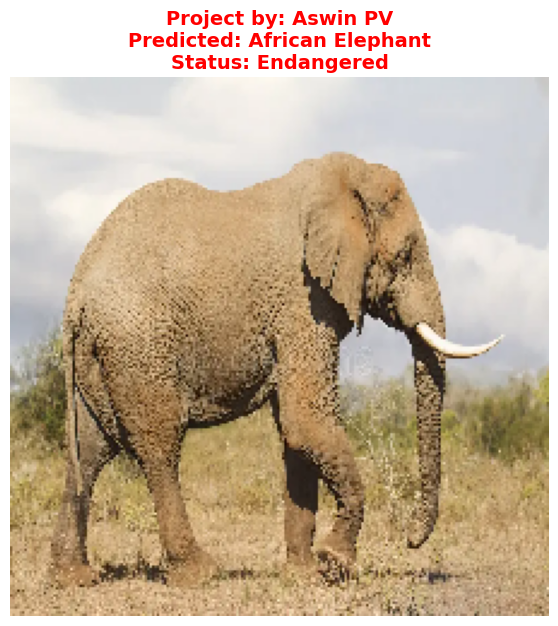

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow import keras
from keras.utils import load_img, img_to_array
from keras.applications.resnet import ResNet101, preprocess_input, decode_predictions
import os

# --- 1. Load pretrained ResNet101 model ---
print("Initializing AI Model (ResNet101)...")
model = ResNet101(weights='imagenet')

# --- 2. Internal Endangered Species Database ---
endangered_species = {
    "common_name": ["African Elephant", "Bengal Tiger", "Indian Elephant", "Giant Panda", "Blue Whale"],
    "conservation_status": ["Endangered", "Endangered", "Endangered", "Vulnerable", "Endangered"]
}
endangered_df = pd.DataFrame(endangered_species)

# --- 3. Image Configuration ---
img_path = "test.jpg"

if not os.path.exists(img_path):
    print(f"ACTION REQUIRED: Please upload an animal image to the Colab sidebar and rename it to '{img_path}'")
else:
    # 4. Preprocess image
    img = load_img(img_path, target_size=(224, 224))
    x = img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    # 5. Predict
    img_pred = model.predict(x)
    img_labels = decode_predictions(img_pred, top=5)[0]

    # 6. Matching Logic
    predicted_label = img_labels[0][1].replace('_', ' ').lower()
    matched = endangered_df[endangered_df["common_name"].str.lower().str.contains(predicted_label)]
    status = matched.iloc[0]["conservation_status"] if not matched.empty else "Not Endangered"

    plt.figure(figsize=(7, 7))
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Project by: Aswin PV\nPredicted: {predicted_label.title()}\nStatus: {status}",
              fontsize=14, color='red', fontweight='bold')
    plt.show()